# Módulo 5: salario frente a producción (¿quién cobra menos que el mercado?)

**Preguntas:**
- ¿Cuánto explica la producción de un jugador (PIE × minutos) de lo que cobra?
- ¿Quién cobra mucho menos (o más) de lo que el mercado paga por una producción parecida, y cuánto de eso es solo un contrato de novato?
- ¿Qué tanto hay que creerle a esa lista?

**Diseño (decidido antes de ver los datos):**
- Producción = **PIE × minutos jugados** (PER y BPM no existen en NBA.com). Solo jugadores de rotación (≥ 1000 minutos).
- Mercado = regresión de **log(salario)** sobre log(producción), edad y una marca de **contrato de novato** (≤ 3 temporadas desde su debut, dato de NBA.com). Sin esa marca, la lista "subvalorados" se llena de novatos por el convenio colectivo, no por el mercado.
- Brecha = salario real / salario de mercado, y **desviaciones** (brecha dividida por la dispersión habitual de las brechas). El intervalo bootstrap solo mide la incertidumbre de la línea de mercado.
- Una sola temporada si el CSV no cubre más (ver sección 0).

**Mi hipótesis previa:** ninguna ("sin intuición, corre"). Referencia: si el mercado pagara exactamente por producción, todas las brechas serían 1.

**Datos de salarios:** CSV de Kaggle (`omarsobhy14/nba-players-salaries`) descargado por ti; licencia sin confirmar, así que queda solo en tu PC (`data/external/`, fuera de git). Por eso las tablas de este notebook muestran **brechas y desviaciones, no dólares**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sportslab.analysis.value import MIN_MINUTES, contribution, market_fit_summary, score_players
from sportslab.config import DATA_DIR
from sportslab.data import NbaClient
from sportslab.data.players import add_experience, load_career_start, load_player_stats
from sportslab.data.salaries import match_salaries, read_salaries

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.2f}".format
pd.options.display.width = 200

client = NbaClient()
salaries = read_salaries(DATA_DIR / "external" / "salaries.csv")
career = load_career_start(client)
print(salaries.groupby("season").size().to_dict())

{'2022-23': 574, '2023-24': 409, '2024-25': 231, '2025-26': 135}


## 0. Lo que encontré en el archivo antes de usarlo

1. **El archivo es ancho** (una columna por temporada, texto `$48,070,014`, `$0` = sin contrato conocido) y la **última columna está mal rotulada**: dice `2024/2025` por segunda vez, pero sus valores son los de **2025-26** (por ejemplo, Stephen Curry $59.6 M y Kevin Durant $54.7 M, que corresponden a ese año). Lo traduje explícitamente en `scripts/prepare_salaries.py`.
2. **Las columnas posteriores a 2022-23 parecen calendarios de contratos conocidos cuando se recogieron los datos**: solo incluyen a quien ya tenía contrato firmado para ese año. Lo medí en vez de suponerlo:

In [2]:
rows = []
for season in ["2022-23", "2023-24", "2024-25", "2025-26"]:
    players = add_experience(load_player_stats(client, [season]), career)
    matched, csv_left, _ = match_salaries(salaries[salaries["season"] == season], players)
    rot = players[players["minutes"] >= MIN_MINUTES]
    rows.append(
        {
            "temporada": season,
            "filas del CSV": int((salaries["season"] == season).sum()),
            "jugadores de rotación": len(rot),
            "con salario": int((matched["minutes"] >= MIN_MINUTES).sum()),
            "cobertura": (matched["minutes"] >= MIN_MINUTES).sum() / len(rot),
        }
    )
cov = pd.DataFrame(rows)
print(cov.to_string(index=False))

temporada  filas del CSV  jugadores de rotación  con salario  cobertura
  2022-23            574                    263          263       1.00
  2023-24            409                    266          209       0.79
  2024-25            231                    270          141       0.52
  2025-26            135                    279           81       0.29


**Solo 2022-23 sirve** (100 % de la rotación). 2023-24 cubre 79 %, 2024-25 52 % y 2025-26 29 %, y los que faltan son justamente quienes firmaron después: un mercado estimado con eso estaría sesgado. Por eso no calculo si la brecha *persiste* entre temporadas: haría falta un CSV completo de al menos dos años. La página de Streamlit lo bloquea con un aviso en lugar de mostrar resultados engañosos.

3. **Cuatro nombres no cruzaban** entre las dos fuentes (Nic/Nicolas Claxton, Santi/Santiago Aldama, Herb/Herbert Jones, Schröder/Schroeder) además de "P.J."/"PJ" y "T.J."/"TJ". Los vi porque el cruce reporta a quién no encontró; ahora hay una tabla de alias con test. Resultado: 263 de 263 jugadores de rotación de 2022-23 con salario.

In [3]:
season = "2022-23"
players = add_experience(load_player_stats(client, [season]), career)
matched, csv_left, players_left = match_salaries(salaries[salaries["season"] == season], players)
rot = players[players["minutes"] >= MIN_MINUTES]
print(
    f"Cruzados: {len(matched)} jugadores; filas del CSV sin cruzar: {len(csv_left)}; "
    f"rotación sin salario: {int((players_left['minutes'] >= MIN_MINUTES).sum())} de {len(rot)}"
)
print(
    "Filas del CSV sin cruzar con mayor salario (nombres; casi todos jugadores que no jugaron esa temporada):"
)
print(", ".join(csv_left.sort_values("salary_usd", ascending=False)["player_name"].head(10)))

Cruzados: 529 jugadores; filas del CSV sin cruzar: 45; rotación sin salario: 0 de 263
Filas del CSV sin cruzar con mayor salario (nombres; casi todos jugadores que no jugaron esa temporada):
Lonzo Ball, Danilo Gallinari, Derrick Favors, Chet Holmgren, Patrick Mills, David Nwaba, Ishmael Smith, Moe Harkless, Josh Primo, Sviatoslav Mykhailiuk


## 1. El mercado: ¿cuánto explica la producción?

Sin control de novato: R² = 0.54, elasticidad = 1.15
Con control de novato: R² = 0.65, elasticidad = 0.96


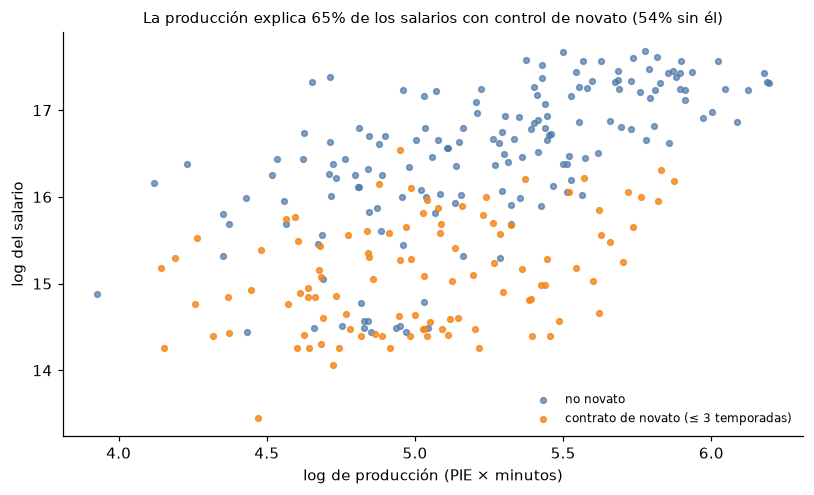

In [4]:
fit_no = market_fit_summary(matched, rookie_control=False)
fit_yes = market_fit_summary(matched, rookie_control=True)
print(f"Sin control de novato: R² = {fit_no['r2']:.2f}, elasticidad = {fit_no['elasticity']:.2f}")
print(f"Con control de novato: R² = {fit_yes['r2']:.2f}, elasticidad = {fit_yes['elasticity']:.2f}")

scored = score_players(matched, rookie_control=True)
x = np.log(contribution(scored))
y = np.log(scored["salary_usd"])
rookie = scored["years_experience"] <= 3
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(x[~rookie], y[~rookie], s=14, color="#4C78A8", alpha=0.7, label="no novato")
ax.scatter(
    x[rookie],
    y[rookie],
    s=14,
    color="#F58518",
    alpha=0.8,
    label="contrato de novato (≤ 3 temporadas)",
)
ax.set_xlabel("log de producción (PIE × minutos)")
ax.set_ylabel("log del salario")
ax.set_title(
    f"La producción explica {fit_yes['r2']:.0%} de los salarios con control de novato "
    f"({fit_no['r2']:.0%} sin él)",
    fontsize=10,
)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** Con el control de novato el modelo explica ~65 % de la variación de los salarios entre jugadores de rotación (sin él, ~54 %). Los puntos naranja (novatos) quedan sistemáticamente por debajo del resto: ese es el contrato fijado por el convenio, no una "ganga" del mercado.

## 2. ¿Y si no controlo por novato?

In [5]:
without = score_players(matched, rookie_control=False)
with_ = scored
top_without = without.nsmallest(15, "ratio")
top_with = with_.nsmallest(15, "ratio")
print(
    f"De los 15 más 'baratos' SIN control, {(top_without['years_experience'] <= 3).mean():.0%} son novatos"
)
print(
    f"De los 15 más 'baratos' CON control, {(top_with['years_experience'] <= 3).mean():.0%} son novatos"
)

De los 15 más 'baratos' SIN control, 73% son novatos
De los 15 más 'baratos' CON control, 7% son novatos


Sin el control, tres de cada cuatro "subvalorados" son simplemente jugadores en los primeros años de su contrato. Con el control cambia por completo la lista, que ahora son mayormente veteranos con contratos bajos.

## 3. Quién está lejos del mercado

Cobran menos de lo que el mercado paga por su producción (en 'ratio', 0.20 = 20 % de lo esperado):
          player team   age  years_experience  minutes  pie  ratio  gap_z
    Drew Eubanks  POR 26.00                 4  1583.40 0.10   0.19  -2.69
Keita Bates-Diop  SAS 27.00                 4  1453.90 0.10   0.20  -2.65
   Thomas Bryant  DEN 25.00                 5  1079.70 0.13   0.21  -2.54
    Shake Milton  PHI 26.00                 4  1565.60 0.09   0.22  -2.51
  Troy Brown Jr.  LAL 23.00                 4  1862.00 0.07   0.22  -2.48
   Moritz Wagner  ORL 26.00                 4  1111.50 0.12   0.22  -2.46
      Damion Lee  PHX 30.00                 5  1509.60 0.08   0.23  -2.43
 Dennis Schröder  LAL 29.00                 9  1986.60 0.08   0.25  -2.29
Kenrich Williams  OKC 28.00                 4  1208.40 0.10   0.25  -2.25
Dennis Smith Jr.  CHA 25.00                 5  1387.80 0.09   0.26  -2.23
     Josh Okogie  PHX 24.00                 4  1353.60 0.08   0.27  -2.15
       KJ Mar

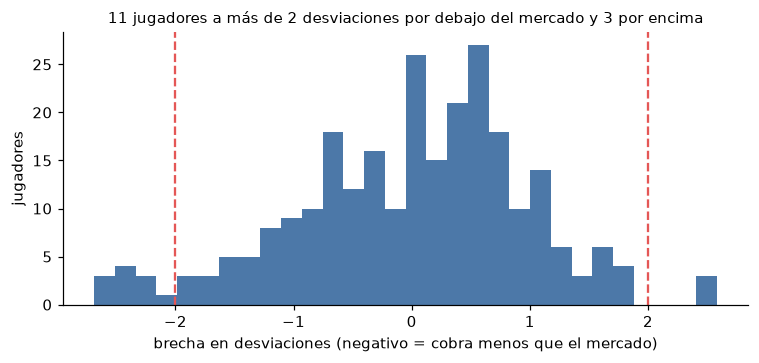

In [6]:
cols = ["player", "team", "age", "years_experience", "minutes", "pie", "ratio", "gap_z"]
print(
    "Cobran menos de lo que el mercado paga por su producción (en 'ratio', 0.20 = 20 % de lo esperado):"
)
print(scored.nsmallest(12, "gap_z")[cols].to_string(index=False))
print()
print("Cobran más:")
print(scored.nlargest(8, "gap_z")[cols].to_string(index=False))
below, above = int((scored["gap_z"] < -2).sum()), int((scored["gap_z"] > 2).sum())
print(
    f"\nA más de 2 desviaciones: {below} por debajo y {above} por encima, de {len(scored)} jugadores "
    f"(por azar con una campana se esperarían ~{0.025 * len(scored):.0f} de cada lado)"
)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(scored["gap_z"], bins=30, color="#4C78A8")
ax.axvline(-2, color="#E45756", ls="--")
ax.axvline(2, color="#E45756", ls="--")
ax.set_xlabel("brecha en desviaciones (negativo = cobra menos que el mercado)")
ax.set_ylabel("jugadores")
ax.set_title(
    f"{below} jugadores a más de 2 desviaciones por debajo del mercado y {above} por encima",
    fontsize=10,
)
plt.tight_layout()
plt.show()

**Lectura.** Los más baratos son jugadores de rotación con 4 o más temporadas (recién salidos del contrato de novato o con contratos de mínimo, ~2 M) y producción sólida (PIE 0.07-0.13 con 1100-2300 minutos): el mercado esperado les pagaba 4-5 veces más. Entre los más caros hay dos tipos: jugadores que **jugaron poco por lesión o ausencias** (Simmons con 1100 minutos, Wiggins con 1200): como la producción es PIE × minutos, quien no juega parece "sobrepagado" sin que su salario sea irracional; y un jugador sano y muy usado como **Dort (2270 minutos, PIE 0.06)**, un especialista defensivo: **PIE no mide bien la defensa**, así que el modelo lo ve caro porque su valor está donde la métrica no mira.

## 4. ¿Cambia si descarto a los lesionados?

In [7]:
healthy = matched[matched["gp"] >= 60]
sc_h = score_players(healthy, rookie_control=True)
fit_h = market_fit_summary(healthy, rookie_control=True)
print(
    f"Con ≥ 60 partidos jugados: {len(sc_h)} jugadores, R² = {fit_h['r2']:.2f}, elasticidad = {fit_h['elasticity']:.2f}"
)
both = scored.merge(sc_h[["player_id", "gap_z"]], on="player_id", suffixes=("", "_sano"))
overlap_low = set(scored.nsmallest(12, "gap_z")["player"]) & set(
    sc_h.nsmallest(12, "gap_z")["player"]
)
overlap_high = set(scored.nlargest(8, "gap_z")["player"]) & set(sc_h.nlargest(8, "gap_z")["player"])
print(f"Correlación de la brecha (todos vs. sanos): {both['gap_z'].corr(both['gap_z_sano']):.2f}")
print(f"De los 12 más baratos, siguen entre los 12 más baratos: {len(overlap_low)}")
print(f"De los 8 más caros, siguen entre los 8 más caros: {len(overlap_high)}")
print("Los más caros entre los sanos:")
print(
    sc_h.nlargest(6, "gap_z")[
        ["player", "team", "age", "years_experience", "minutes", "pie", "ratio", "gap_z"]
    ].to_string(index=False)
)

Con ≥ 60 partidos jugados: 210 jugadores, R² = 0.68, elasticidad = 1.06
Correlación de la brecha (todos vs. sanos): 1.00
De los 12 más baratos, siguen entre los 12 más baratos: 8
De los 8 más caros, siguen entre los 8 más caros: 5
Los más caros entre los sanos:
             player team   age  years_experience  minutes  pie  ratio  gap_z
      Luguentz Dort  OKC 24.00                 3  2271.80 0.06   5.13   2.85
   Matisse Thybulle  POR 26.00                 3  1199.90 0.06   3.40   2.13
Talen Horton-Tucker  UTA 22.00                 3  1313.00 0.10   3.32   2.09
    De'Andre Hunter  ATL 25.00                 3  2123.90 0.07   3.26   2.06
        Isaac Okoro  CLE 22.00                 2  1649.20 0.06   3.07   1.96
 Michael Porter Jr.  DEN 25.00                 4  1798.00 0.10   2.80   1.79


Entre jugadores con ≥ 60 partidos, la lista de "baratos" se mantiene en buena parte (8 de 12) y la de "caros" cambia en parte (5 de 8): Simmons y Wiggins salen, y quedan jugadores sanos y jóvenes (22-26 años, 2-4 temporadas) con PIE bajo para su contrato, varios de ellos especialistas defensivos (Dort, Thybulle, Okoro) cuyo valor PIE no captura. Esa es una pregunta más interesante que la de los lesionados: la medida de producción tiene un punto ciego.

## 5. Resultado vs. hipótesis

No hubo hipótesis previa. Contra la referencia "el mercado paga exactamente por producción":

| Pregunta | Resultado (2022-23, 263 jugadores de rotación) | Veredicto |
|---|---|---|
| ¿Cuánto explica la producción? | R² ≈ 0.65 con control de novato (0.54 sin él) | Bastante, no todo |
| ¿Importa el contrato de novato? | 73 % → 7 % de novatos entre los 15 más baratos | Es el principal sesgo de la lista |
| ¿Quién está lejos del mercado? | 11 a más de 2 desviaciones por debajo (por azar: ~7) y 3 por encima | Pocos casos y poco más de lo esperable por azar |
| ¿Persiste la brecha? | No se pudo medir: el CSV solo cubre bien 2022-23 | Sin respuesta |

**Qué NO dice:** que esos jugadores "valgan" más. PIE no mide bien la defensa ni el espaciado, la producción se mide después y el salario se fijó antes (el contrato es una apuesta), y un solo año puede ser ruido.

**Qué mejorar (no hecho):** un CSV completo de varias temporadas (para medir persistencia y separar ruido de brecha real); años de contrato restantes y tipo de contrato; una medida de producción con defensa; modelar la lesión explícitamente.

## 6. Tus ejercicios

1. **Predice y mide.** Cambia el límite de novato de 3 a 4 temporadas en `design()` (archivo `sportslab/analysis/value.py`). Antes de correr, predice si el R² sube o baja, y por qué (¿cuántos jugadores cambian de grupo?).
2. **Un caso.** Elige a un jugador de los "baratos" y averigua por qué cobraba tan poco (¿mínimo veterano?, ¿contrato anterior a su ascenso?). Qué dato faltaría para que el modelo lo explicara.